<a href="https://colab.research.google.com/github/garrettspringsted/STAT-7110-Quality-Control/blob/Assignment--3/Copy_of_STAT_7110_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 23, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

In [17]:
## Define & Measure
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "garrettspringsted"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture:

setwd("/content/STAT-7110-Quality-Control/Assignments/HW3")
getwd()
list.files()

[1] "/content/STAT-7110-Quality-Control/Assignments/HW3"

[1] "RavisComics_BackIssueDefectCounts.xlsx"    
[2] "RavisComics_NewReleaseDefectCounts.xlsx"   
[3] "RavisComics_ShipmentCondition_PhaseI.xlsx" 
[4] "RavisComics_ShipmentCondition_PhaseII.xlsx"
[5] "STAT-7110-HW3.ipynb"                       
[6] "STAT-7110-Quality-Control"

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

### A3: The purpose of this analysis is to evaluate both the frequnecy and severity of damaged comics at Ravi's Comics and Games, Using p, np,c, and u control charts, I will determine whether the damage rates are stable over time, look for unusual patterns and evaluate whether the distributor's improvement were effective. Then, I will assess whether the damage. may be happening during shipping or in-store with customers handling the comics.



### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.

### A2: The pass/fail condition check is binomial attribute data, since each comic is classified as either conforming or nonconforming. The detailed defect count is a Poisson attribute data, since it counts the number of individual defects, and just one comic can have multiple defects. Unlike the previous homeworks we are using discrete, attribute data and represents classifications and counts rather than measurements. So, we are using p, np, c, and u control charts instead of control charts for continuous measurements.


### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?

### A3:For the pass/fail data, the practical factor is whether the sample size remains constant or varies. A p chart is appropriate when sample sizes vary because it tracks the proportion of nonconforming comics, while an np chart tracks the number of nonconforming comics and requires a constant sample size. As for the detailed defect count data, a c chart is appropriate when the inspection unit or area of opportunity remains constant, while a u chart is appropriate when sample sizes vary because it tracks the average number of defects per unit.


## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

### A4: The beginning Phase 1 p chart showed that the process was not in statistical control. Week 14 was above the control limit. This increase may have stemmed from an dramatic increase in damaged comics resulting from several variables including poor packaging , handling issues during and after delivery, or shipping damage.

###I removed Week 14 and generated the control limits again. The new p chart showed no points outside of the control limits and no run-rule violations which had appeared in the original. The revised center line was 0.05162 which indicates an average nonconforming rate of approximately 5.16%. The revised Phase 1 process appears to be in statistical control.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



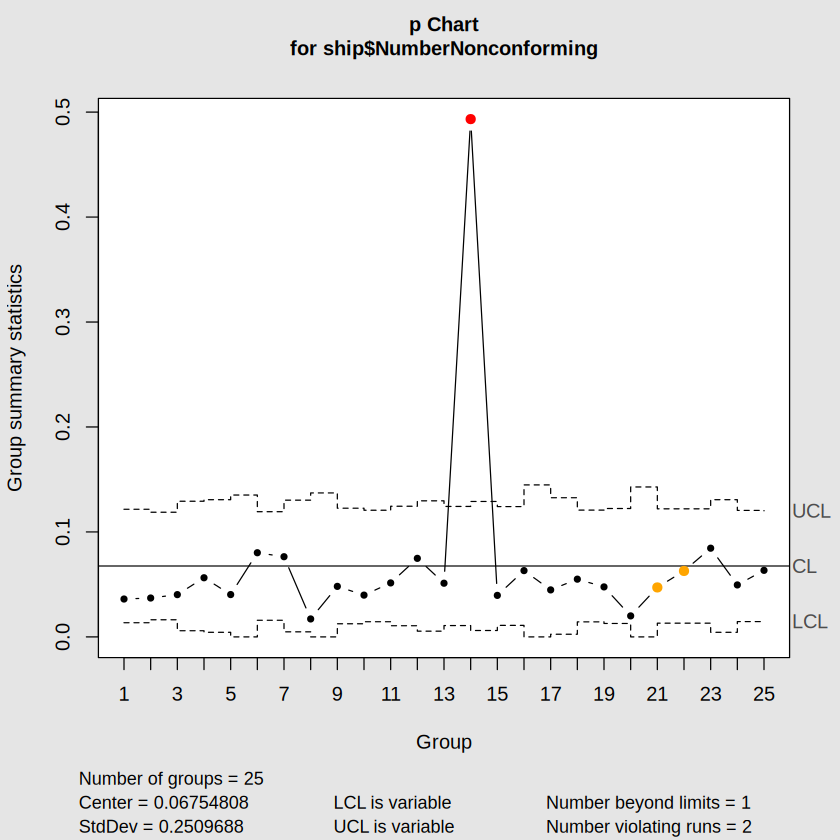

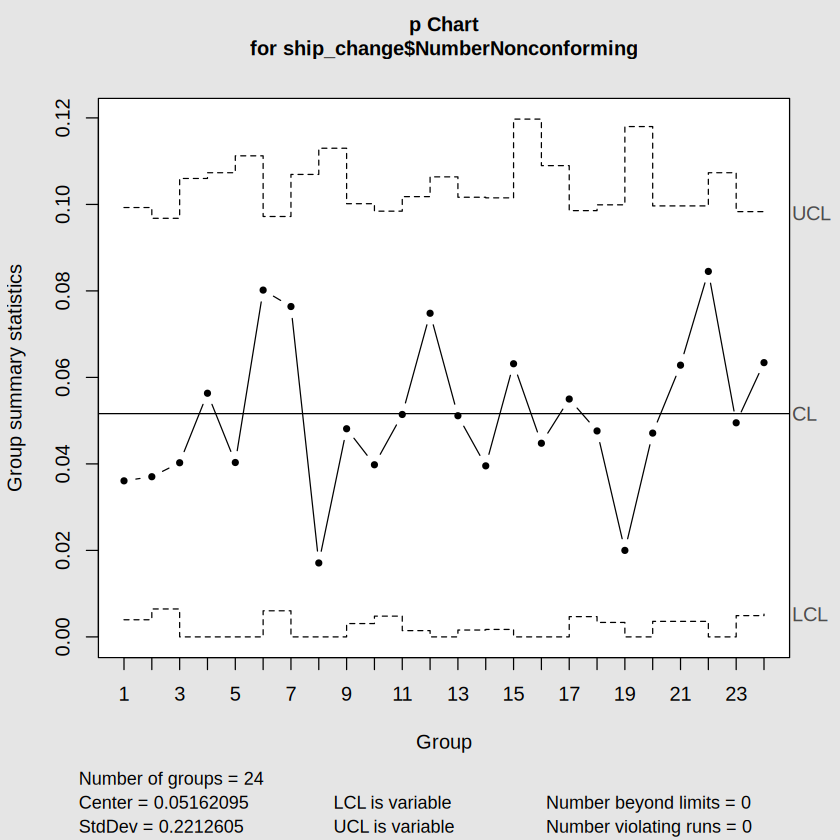

In [18]:
install.packages("qcc", repos="https://cloud.r-project.org/")
library(readxl)
library(qcc)

ship<- read_xlsx("RavisComics_ShipmentCondition_PhaseI.xlsx")

p_chart<- qcc(ship$NumberNonconforming,
              type="p",
              sizes=ship$TotalComics,
              plot=TRUE)

ooc_points<-p_chart$violations$beyond.limits

ship_change<-ship[-ooc_points,]

p_chart_change <-qcc(
  ship_change$NumberNonconforming,
  type="p",
  sizes=ship_change$TotalComics,
  plot=TRUE
)

### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

###A5:The np chart shows the same result as the p chart from question 4. Week 14 was still the only week outside of the control limits, I removed Week 14 and recalculated the limits and they all fell within the control limits.
###In my opinion, both chart can be useful. I think the np chart would be easier for distributors because it shows the actual number of damaged comics compared to the p chart which shows percentages. On the other hand the p chart is better for looking week after week since the shipment sizes vary.

[1] 14

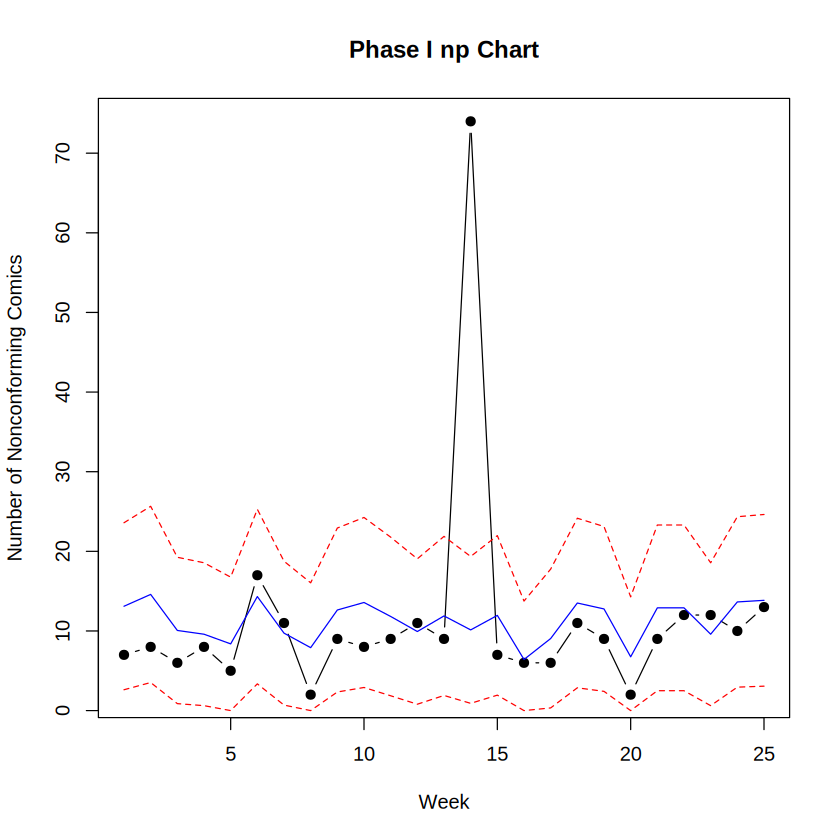

integer(0)


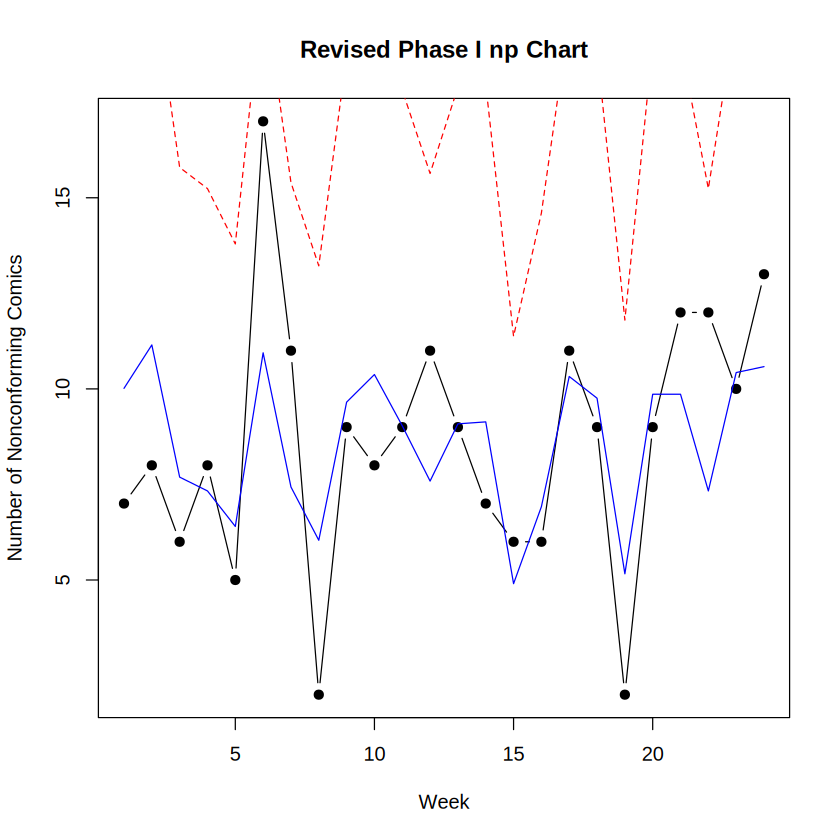

In [19]:
pbar<-sum(ship$NumberNonconforming)/sum(ship$TotalComics)

n<- ship$TotalComics
np<-ship$NumberNonconforming

CL<-n *pbar
UCL<-n*pbar+3*sqrt(n*pbar*(1-pbar))
LCL<-pmax(0, n*pbar-3*sqrt(n*pbar*(1-pbar)))

which(np>UCL|np<LCL)


plot(1:length(np),np,
              type="b",
              pch=19,
              xlab="Week",
              ylab="Number of Nonconforming Comics",
              main="Phase I np Chart")

lines(CL,col="blue")
lines(UCL, col="red", lty=2)
lines(LCL, col="red", lty=2)


## New Chart ##

ooc_points_np<-which(np>UCL|np<LCL)

ship_np_change<-ship[-ooc_points_np,]

pbar_new<-sum(ship_np_change$NumberNonconforming)/sum(ship_np_change$TotalComics)

n_new<- ship_np_change$TotalComics

np_new<- ship_np_change$NumberNonconforming

CL_new<- n_new *pbar_new

UCL_new <-n_new *pbar_new + 3*sqrt(n_new*pbar_new*(1-pbar_new))

LCL_new<-pmax(0,n_new*pbar_new-3*sqrt(n_new*pbar_new*(1-pbar_new)))

##New PLot##
plot(1:length(np_new), np_new,
               type="b",
               pch=19,
               xlab="Week",
               ylab="Number of Nonconforming Comics",
               main="Revised Phase I np Chart")

lines(CL_new,col="blue")
lines(UCL_new, col="red", lty=2)
lines(LCL_new, col="red", lty=2)

print(which(np_new>UCL_new|np_new<LCL_new))

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

###A6: I will carry forward the CL of 0.05162 into Phase II
###The control limits vary week to week so there is no 1 answer to carry forward. we do have the formulas.
###UCL=0.05162 + 3*sqrt((0.05162* (1-0.05162))/n)

###LCL=0.05162 - 3*sqrt((0.05162* (1-0.05162))/n)


## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.
###A7:Using the Original Phase 1 control limits would not be avisable as they included the Week 14,out of control limit, which showed an unusually high number of damaged comics. The increase in damage made the control limits wider. If we included the original limits it would be harder to tall if the new stiffeners actually improve the rate of damaged comics during the shipping process. The new limits give us a narrower control limits which in turn will be a more accurate baseline for comparison.


## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

###A8: After reviweign the chart I can say that non eof the Phase 2 weeks fall outside the control limits. Most of the weeks fall below the CL of 0.05162 suggesting that the damage rate decreased after the addition of the cardboard stiffeners. This result supports that conclusion that the addition of the cardboard stiffeners improved the shipping process. I will report a concern that there is a signiicant run violation.

integer(0)

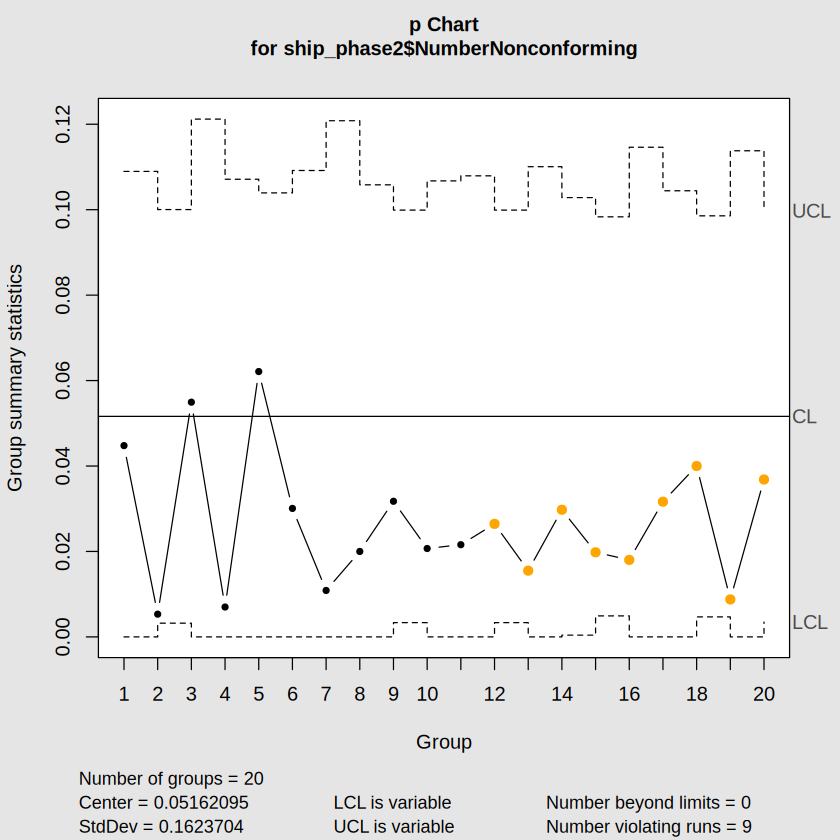

In [21]:
ship_phase2<-read_xlsx("RavisComics_ShipmentCondition_PhaseII.xlsx")

pbar<-p_chart_change$center
n<-ship_phase2$TotalComics

UCL<-pbar+3*sqrt(pbar*(1-pbar)/n)
LCL<-pmax(0, pbar-3*sqrt(pbar*(1-pbar)/n))

##Phase 2 p chart

p_chart_phase2<-qcc(
  ship_phase2$NumberNonconforming,
  type="p",
  sizes=ship_phase2$TotalComics,
  limits=cbind(LCL,UCL),
  center=pbar,
  plot=TRUE
)

##Outside Limits
p_chart_phase2$violations$beyond.limits

### Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

###A9: The np CHart for Phase 2 showed no weeks outside of the control limit which aligns with the results of Question 8. Most weeks had less damage than expected based on the center line. The results found here reinforce the conclusion that the cardboard stiffeners did helps reduce damage during shipping.

integer(0)


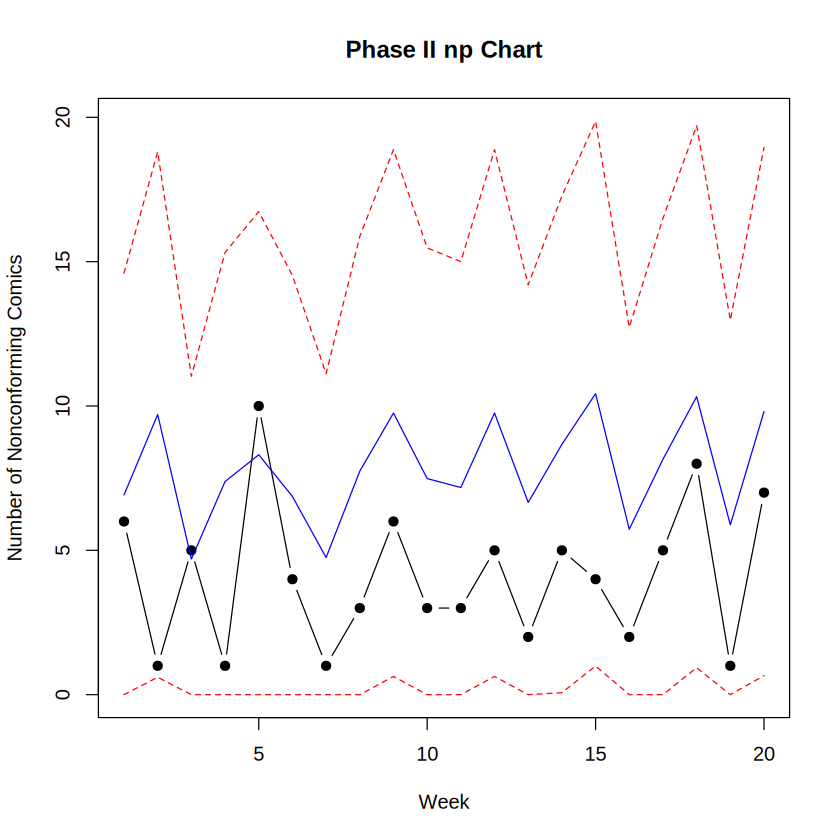

In [22]:
## Q9 Code ##
n<-ship_phase2$TotalComics
np<-ship_phase2$NumberNonconforming

CL<-n*pbar
UCL<- n*pbar+3*sqrt(n*pbar*(1-pbar))
LCL<-pmax(0, n*pbar-3*sqrt(n*pbar*(1-pbar)))

plot(1:length(np),np,type="b", pch=19,
              xlab="Week",ylab="Number of Nonconforming Comics",
              main="Phase II np Chart",
              ylim=range(c(np,LCL,UCL)))

lines(CL, col="blue")
lines(UCL, col="red",lty=2)
lines(LCL, col="red", lty=2)

print(which(np>UCL|np<LCL))

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

###A10:The initial c chart showed that the process was not in statistical control. Week 8 fell extremely outside the UCL. This could be a result of packaging issues , damaged during shipping, or poor handling. I moved forward with removing Week 8 and recalculating the control limits, the remaining weeks fell withing the control limits. Again the was a run violation which may indicate a remaining issue.

[1] 8

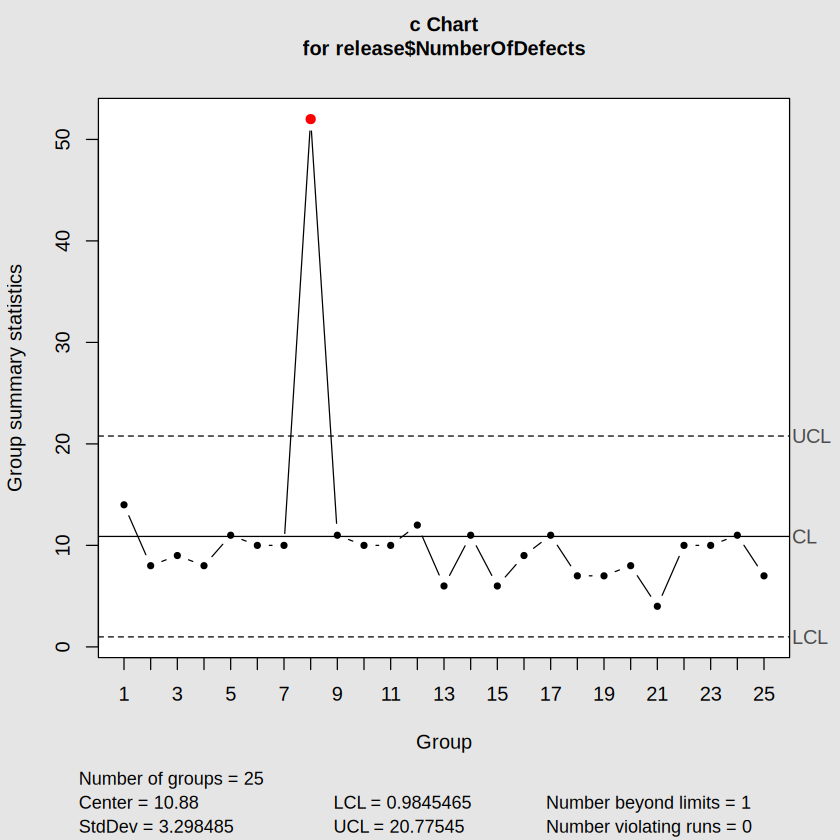

integer(0)

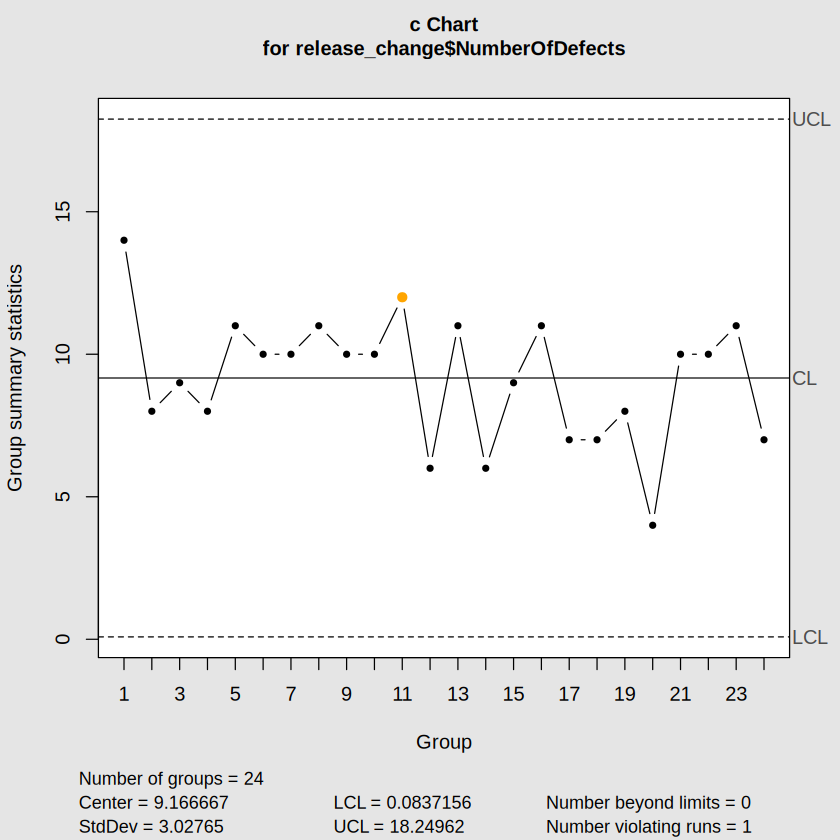

In [23]:
## Q10 Code ##
# c Chart

release<-read_xlsx("RavisComics_NewReleaseDefectCounts.xlsx")

c_chart<-qcc(release$NumberOfDefects,
             type="c", plot=TRUE)

# out of control
ooc_points<-c_chart$violations$beyond.limits
ooc_points

##remove Week 8
release_change<-release[-ooc_points,]

c_chart_change <-qcc(release_change$NumberOfDefects,
                     type="c", plot=TRUE)

##Check for violations again
c_chart_change$violations$beyond.limits

### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

###A11:The final c chart has a c-bar of 9.16667, an UCL of 18.24562, and an LCL of 0.08716.

###A key distinction between the pass/fail analyses in Questions 4-9 and the c-chart is that the c chart tracks the total number of actual defects on the comics where questions 4-9 just indicated damaged or not damaged. This would tell Ravi how many individual defects are occuring, including multiples on the same comic.

In [24]:
## Q11 Code ##

### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

### A12: The initial u-chart showed that the process was not in statistical control. Week 17 was well above the UCL. This high number of defects per box could have been caused by many factors including poor packaging, damage during shipping, damage during storage, or even poor handling.
### I then removed Week 17 and recalculated the control limits. After recalculating, the remaining weeks fell within the control limits. No other points were out of control and there were also no run violations. The process is now in statistical control.

[1] 17

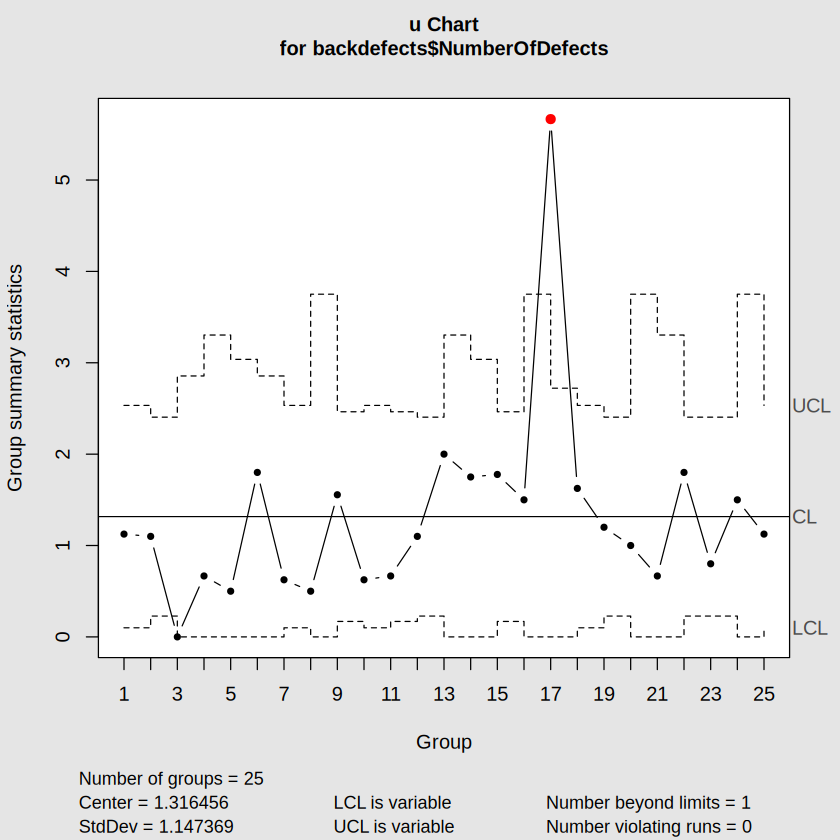

integer(0)

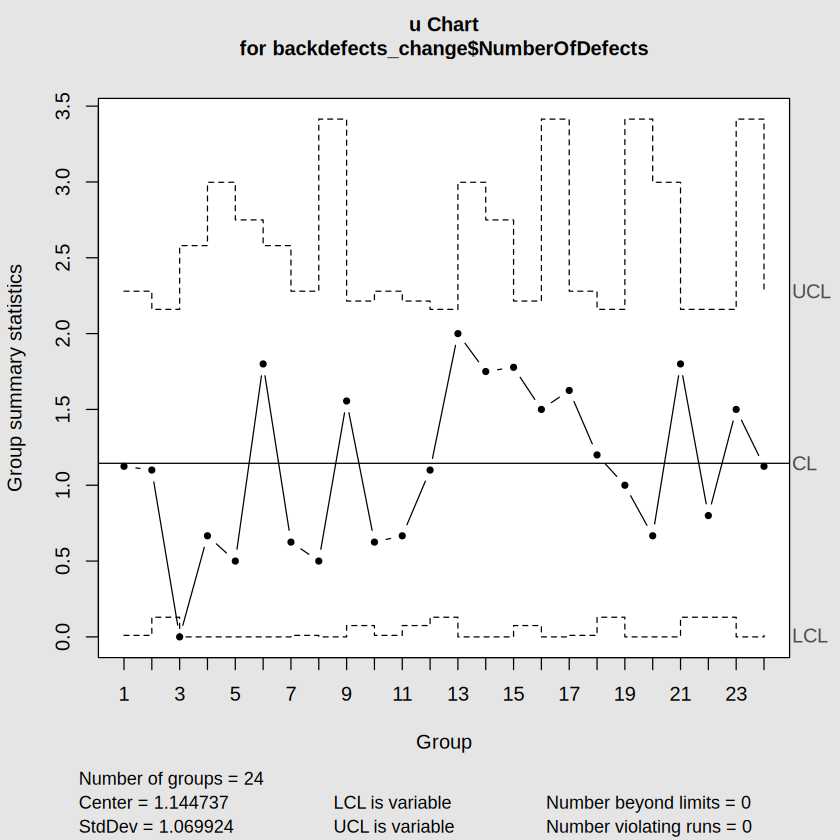

In [26]:
## Q12 Code ##
backdefects<-read_xlsx("RavisComics_BackIssueDefectCounts.xlsx")

u_chart<-qcc(backdefects$NumberOfDefects,
             type="u",
             sizes=backdefects$BoxesInspected,
             plot=TRUE)

ooc_points<- u_chart$violations$beyond.limits
ooc_points

##Remove Point

backdefects_change<-backdefects[-ooc_points, ]

## new u chart

u_chart_update <- qcc(backdefects_change$NumberOfDefects,
                      type="u",
                      sizes=backdefects_change$BoxesInspected,
                      plot=TRUE)

## ooc check
u_chart_update$violations$beyond.limits

### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

###A13: A c chart would not be appropriate because the number of boxes inspected varies each week. The c chart assumes that the sampling unit is consistent from sample to sample. However, since the sample sizes vary in Dataset C, a u chart is more appropriate because it monitors the average number of nonconformities per sample and accounts for the different sample sizes.

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?

### A14: The p and np charts suggest that much of the shipping damage is likely the distributor's responsibility. In Phase 1, Week 14 was above the UCL, indicating an unusually high number of nonconforming comics. After removing Week 14, the process was in statistical control with an average proportion of nonconforming comics of 0.05162. In Phase 2, after the cardboard stiffeners were added, the remaining 20 weeks fell within the control limits, and most weeks showed reduced damage. This suggests that the additional packaging helped reduce damage during shipping. Again, this points towards the distributor's responsibility.

### The c and u charts also identified unusual defects. The c chart for new-release comics showed Week 8 above the UCL, while the u chart for back-issue comics showed Week 17 above the UCL. After removing these weeks and recalculating the control limits, both charts showed no additional points outside the control limits. These results suggest that there may also be issues with how the comics are handled or stored within the shop, although the charts cannot pinpoint the exact cause.

### Overall, Ravi should speak with the distributor regarding the shipping damage and report that the cardboard stiffeners have greatly improved the process. He then should also review the shop's handling and storage procedures to determine whether some of the defects are occurring internally.